In [ ]:
import numpy as np
import marimo as mo
import seaborn as sns
import scipy as scp
import pandas as pd
import matplotlib.pyplot as plt
import altair as alt
from mpl_toolkits.mplot3d import Axes3D

In [ ]:
scores_dataframe = pd.read_csv("./Data/AnalysisData/sensitivity_analysis_summary_scores.csv")

# Sensitivity analysis; Figure S1
## Goal
1. To indentify parameters that are ideal for testing the model in different situations and,
2. To find the parameters that most influece model outcome!

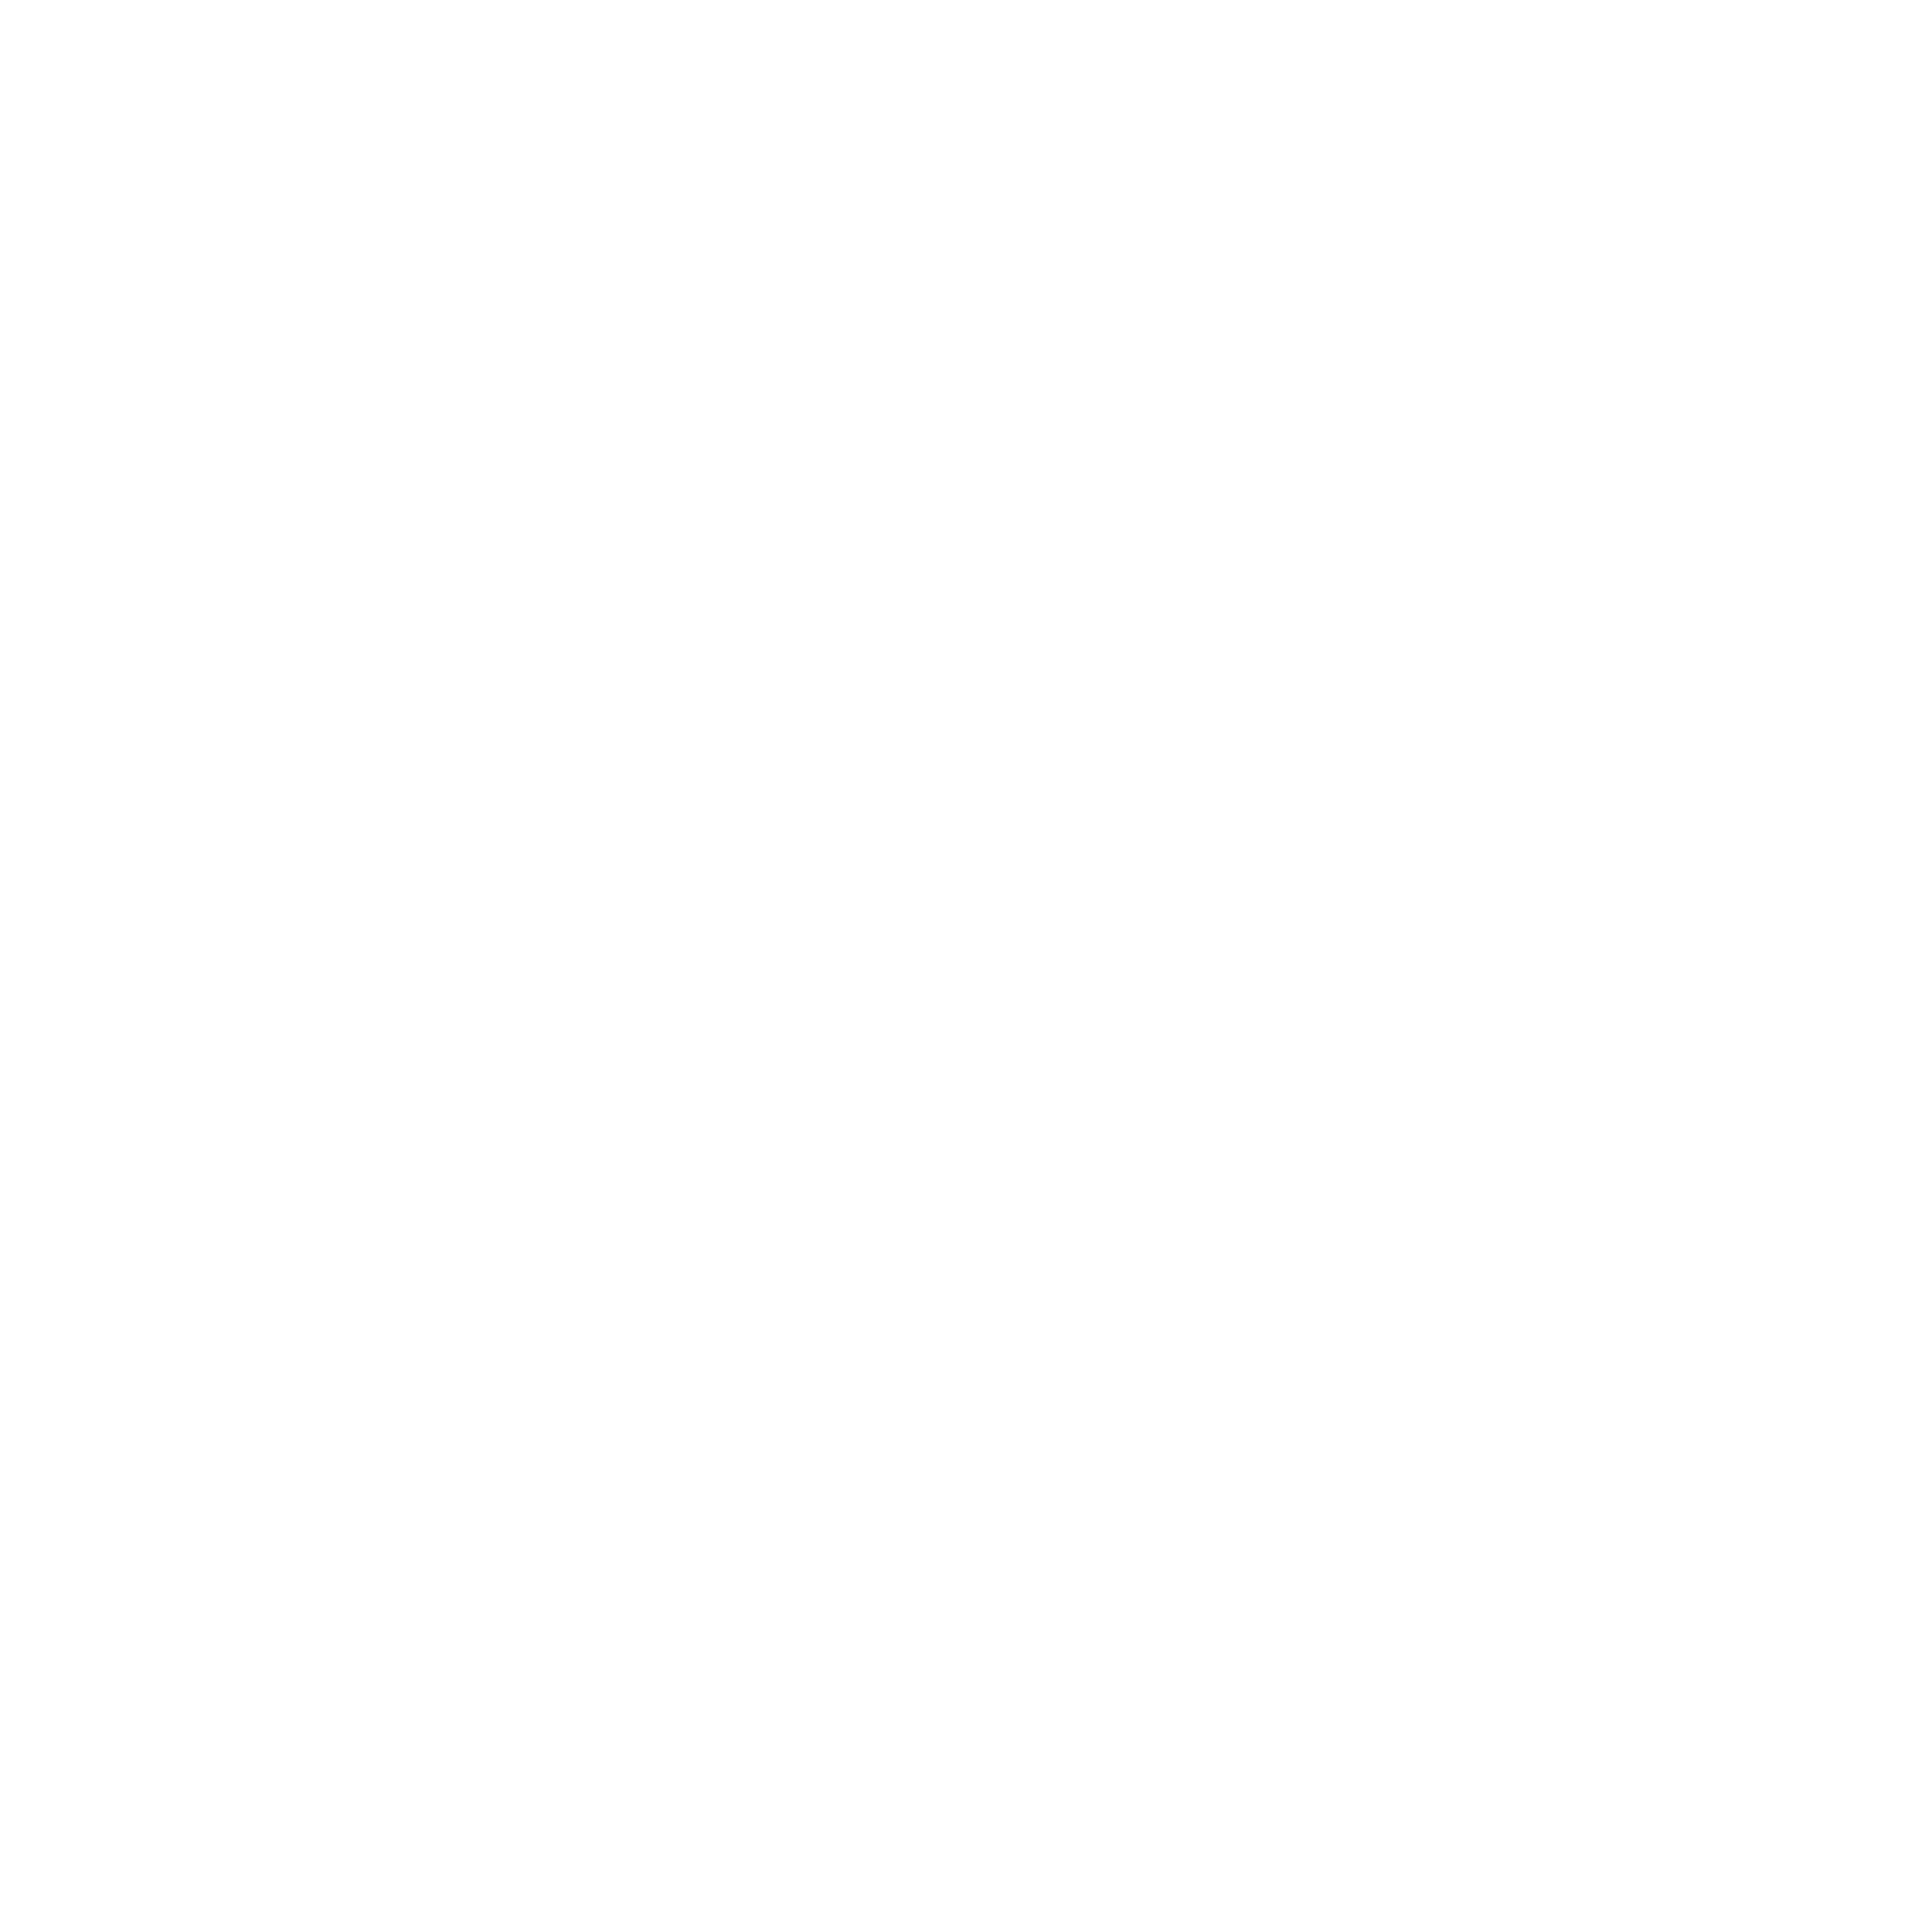

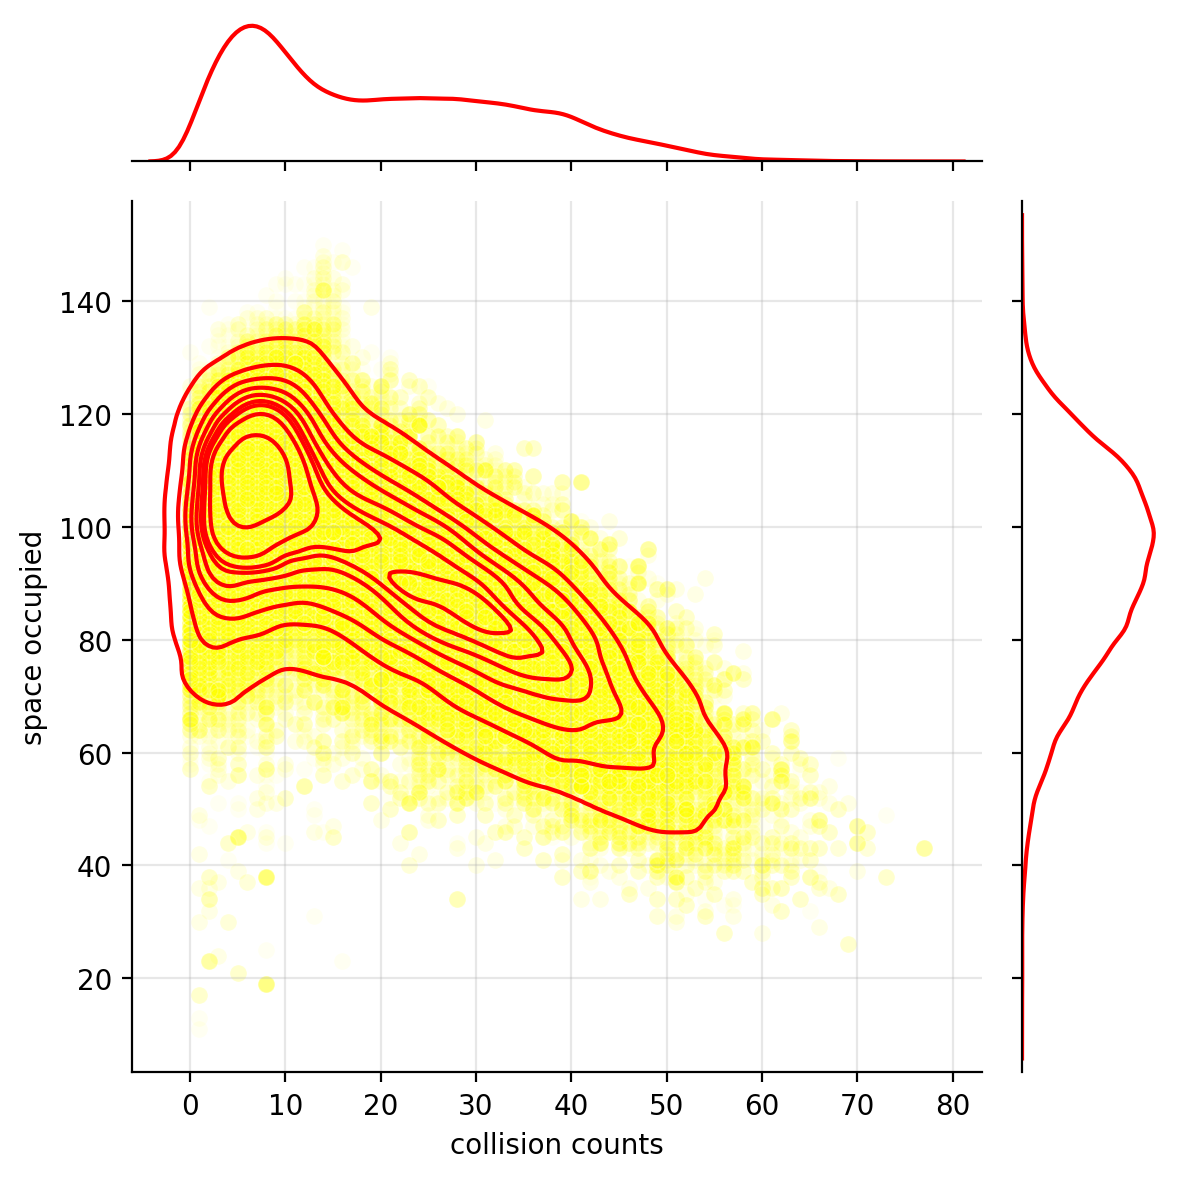

In [ ]:
plt.figure(figsize=(10,10))
sns.jointplot(scores_dataframe, x="wall collision total", y="space_occupied", kind="kde", color="red")
sns.scatterplot(scores_dataframe, x="wall collision total", y="space_occupied", alpha =0.05, color="yellow")
plt.ylabel("space occupied")
plt.xlabel("collision counts")
# plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("./kde_scatterplot.png", transparent= True)
plt.show()

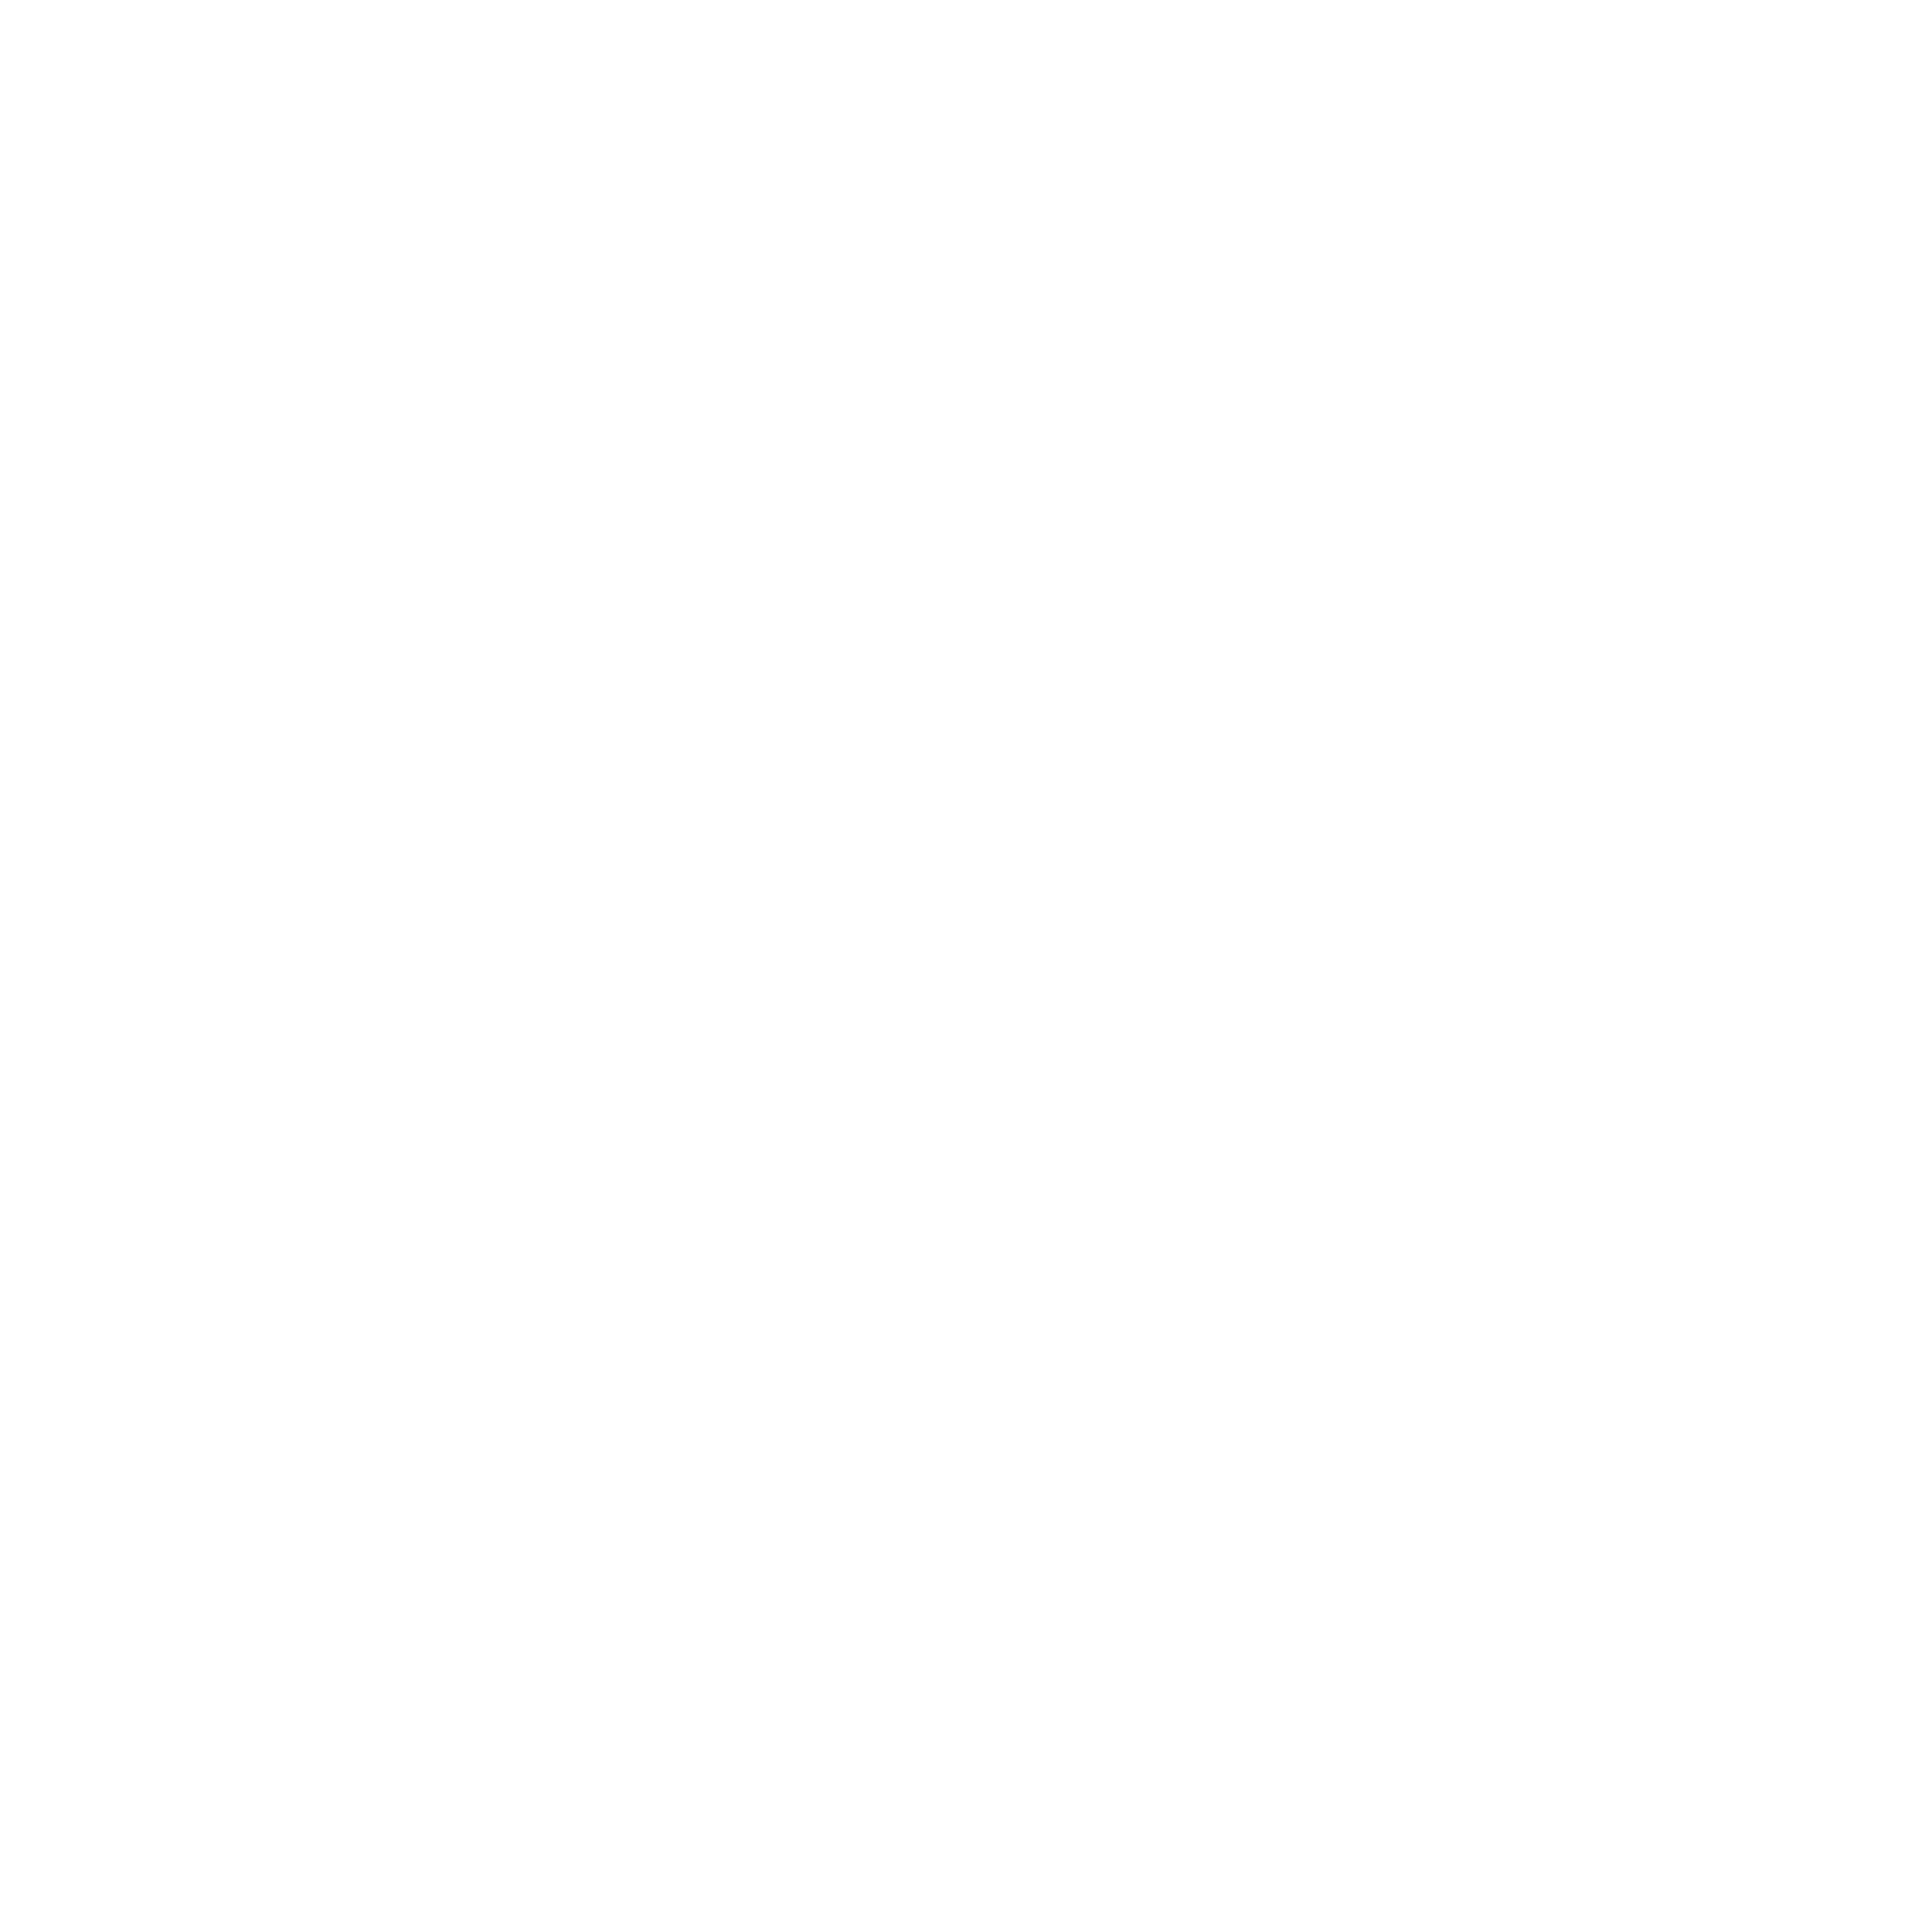

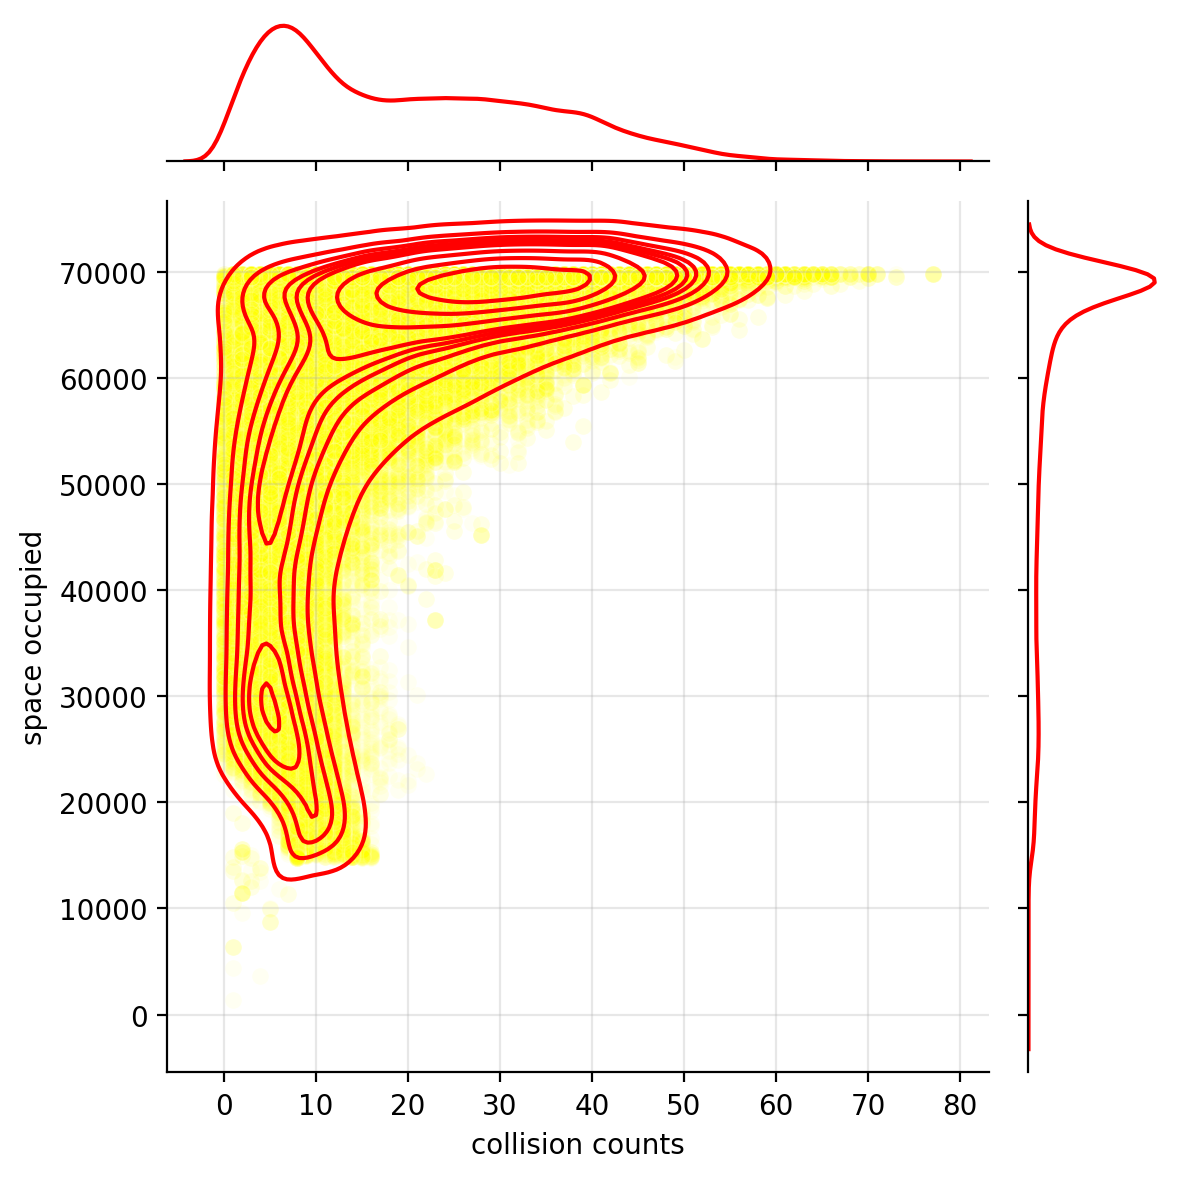

In [ ]:
plt.figure(figsize=(10,10))
sns.jointplot(scores_dataframe, x="wall collision total", y="duration", kind="kde", color="red")
sns.scatterplot(scores_dataframe, x="wall collision total", y="duration", alpha =0.05, color="yellow")
plt.ylabel("space occupied")
plt.xlabel("collision counts")
# plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("./kde_scatterplot_2.png", transparent= True)
plt.show()

In [ ]:
chart = mo.ui.altair_chart(alt.Chart(scores_dataframe).mark_point().encode(
    x='wall collision total',
    y='duration',
    color='space_occupied'
))

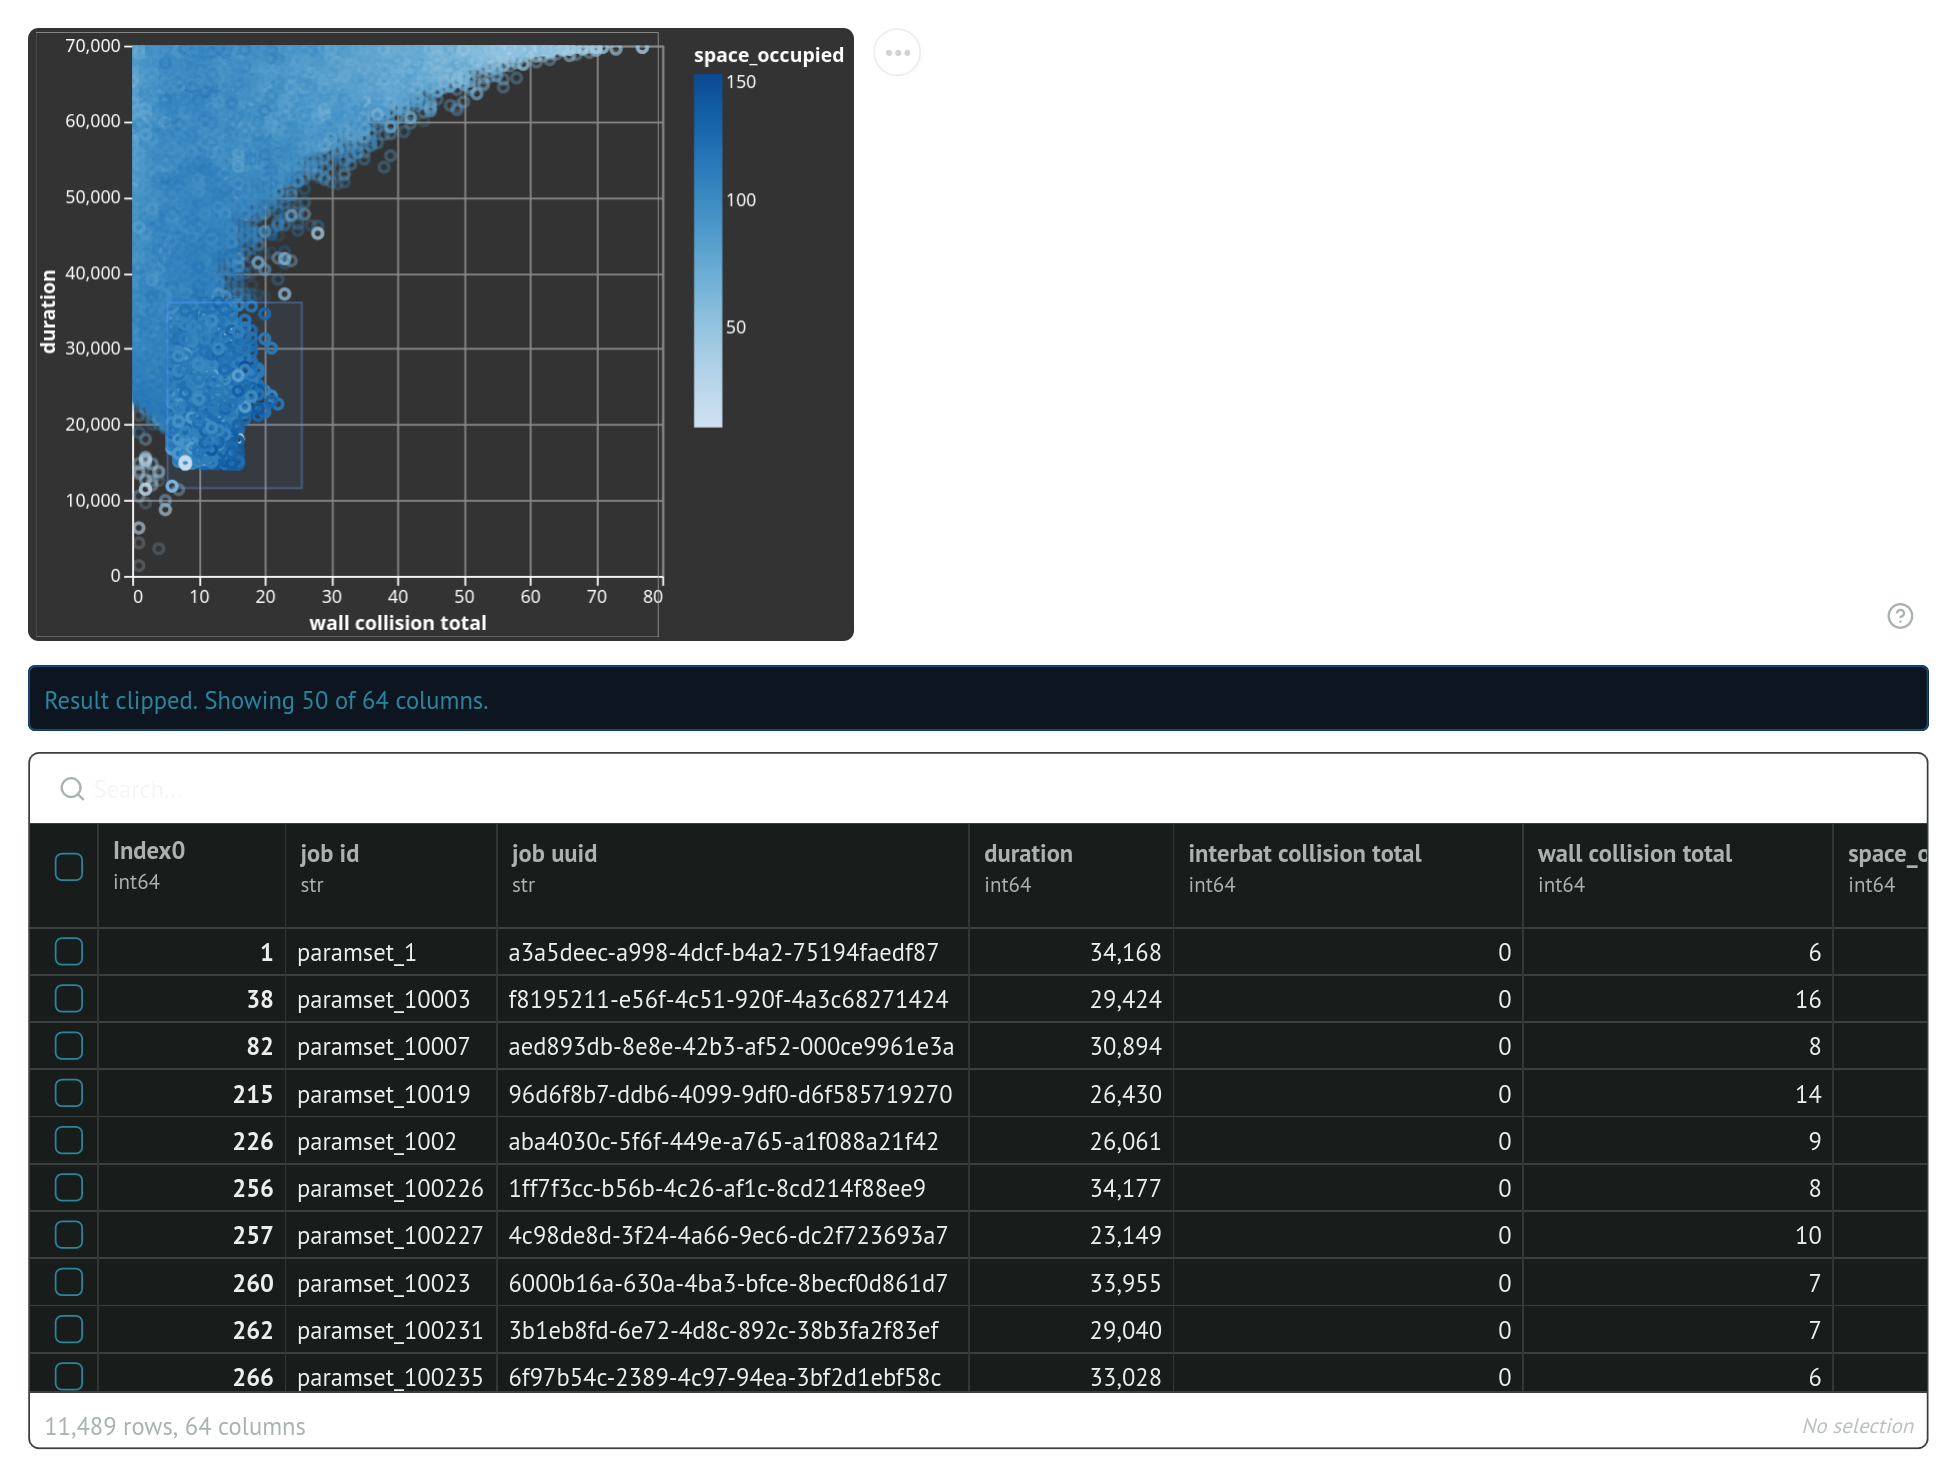

In [ ]:
mo.vstack([chart, mo.ui.table(chart.value)])

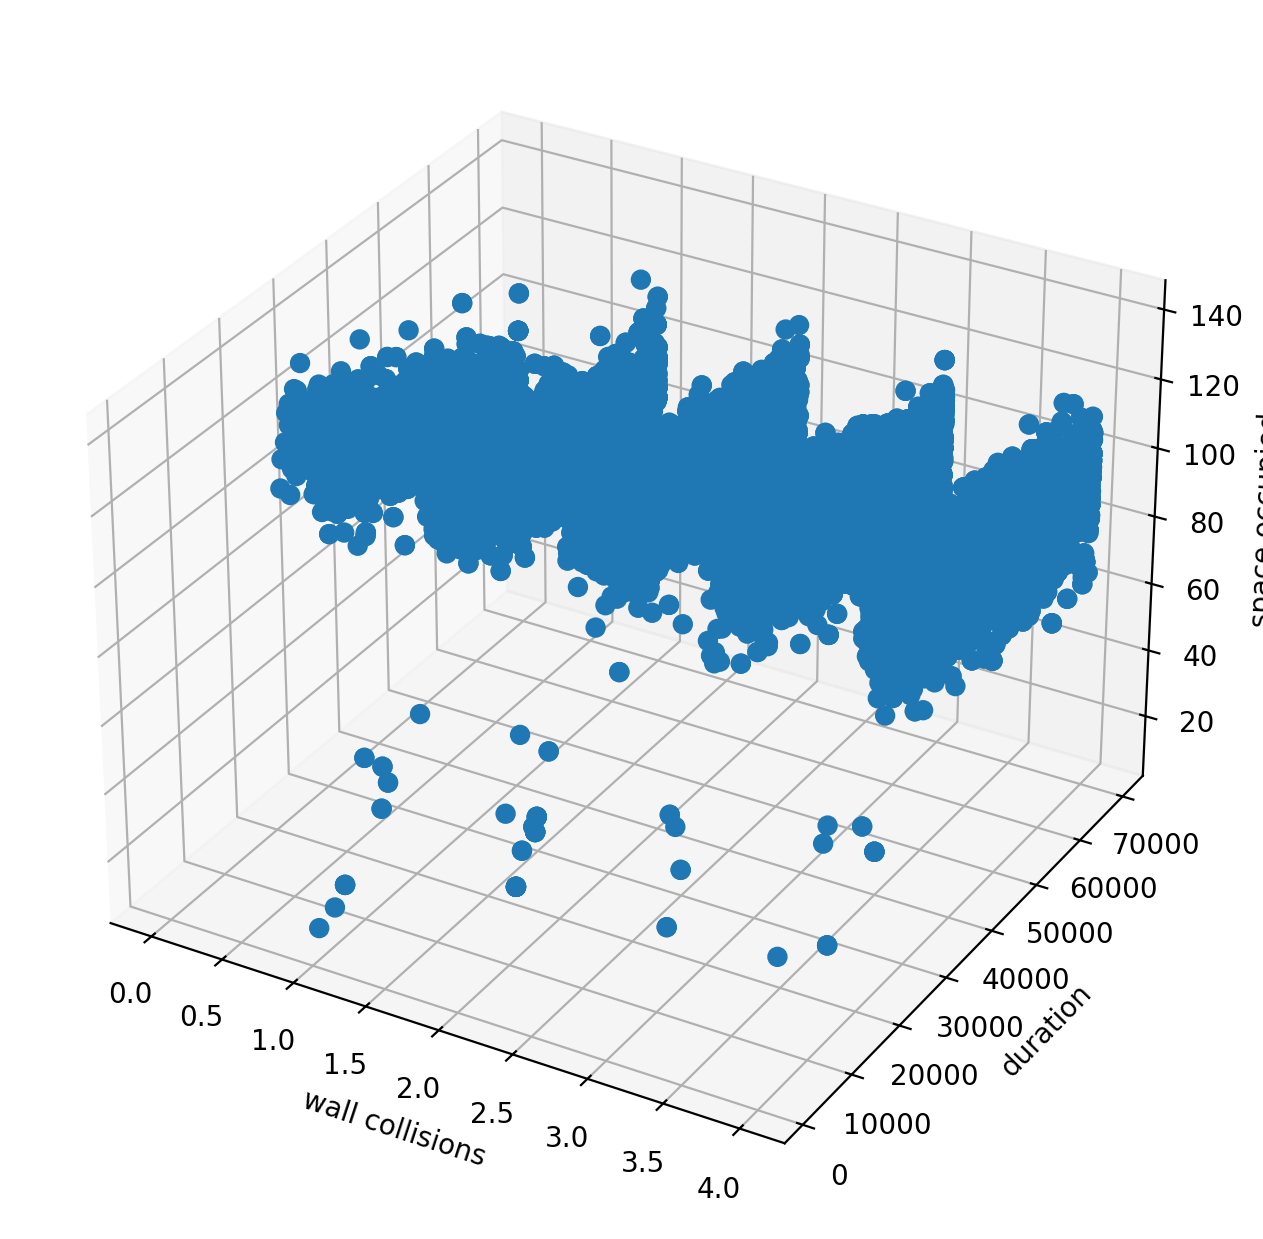

In [ ]:
subset_dataframe = scores_dataframe[scores_dataframe["wall collision total"]<5]
fig = plt.figure(figsize=(6,6))
ax = Axes3D(fig, auto_add_to_figure=False)
fig.add_axes(ax)
sc = ax.scatter(subset_dataframe["wall collision total"], subset_dataframe["duration"], subset_dataframe["space_occupied"], s=40, marker='o', alpha=1)
ax.set_xlabel('wall collisions')
ax.set_ylabel('duration')
ax.set_zlabel('space occupied')
plt.show()

In [ ]:
varying_params = np.array([
    "CALL_RATE_FAST",
    "CALL_DIRECTIONALITY",
    "EMITTED_SPL",
    "HEARING_THRESHOLD",
    "BAT_RADIAL_RESOLUTION",
    "BAT_ANGULAR_RESOLUTION",
    "BAT_FRONTAL_RANGE",
    "CONSISTENCY_TIME_DELAY_CAP",
    "MEMORY_WINDOW_FOR_CONSISTENCY",
])
labels = np.array(['fast call rate (Hz)', 'call directionality', 'emitted spl', 'hearing threshold (dB)', 'radial resolution', 'angular resolution', 'frontal range (degrees)', 'consistency time delay cap', 'memory window'])
number_of_params = len(varying_params)

/tmp/marimo_2590111/__marimo__cell_DxZN_.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df_low_collisions_given_bat_speed, x=param, stat="percent", palette="viridis")
/tmp/marimo_2590111/__marimo__cell_DxZN_.py:15: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend(title= labels[list(varying_params).index(param)])
/tmp/marimo_2590111/__marimo__cell_DxZN_.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df_low_collisions_given_bat_speed, x=param, stat="percent", palette="viridis")
/tmp/marimo_2590111/__marimo__cell_DxZN_.py:15: UserWarning: No art

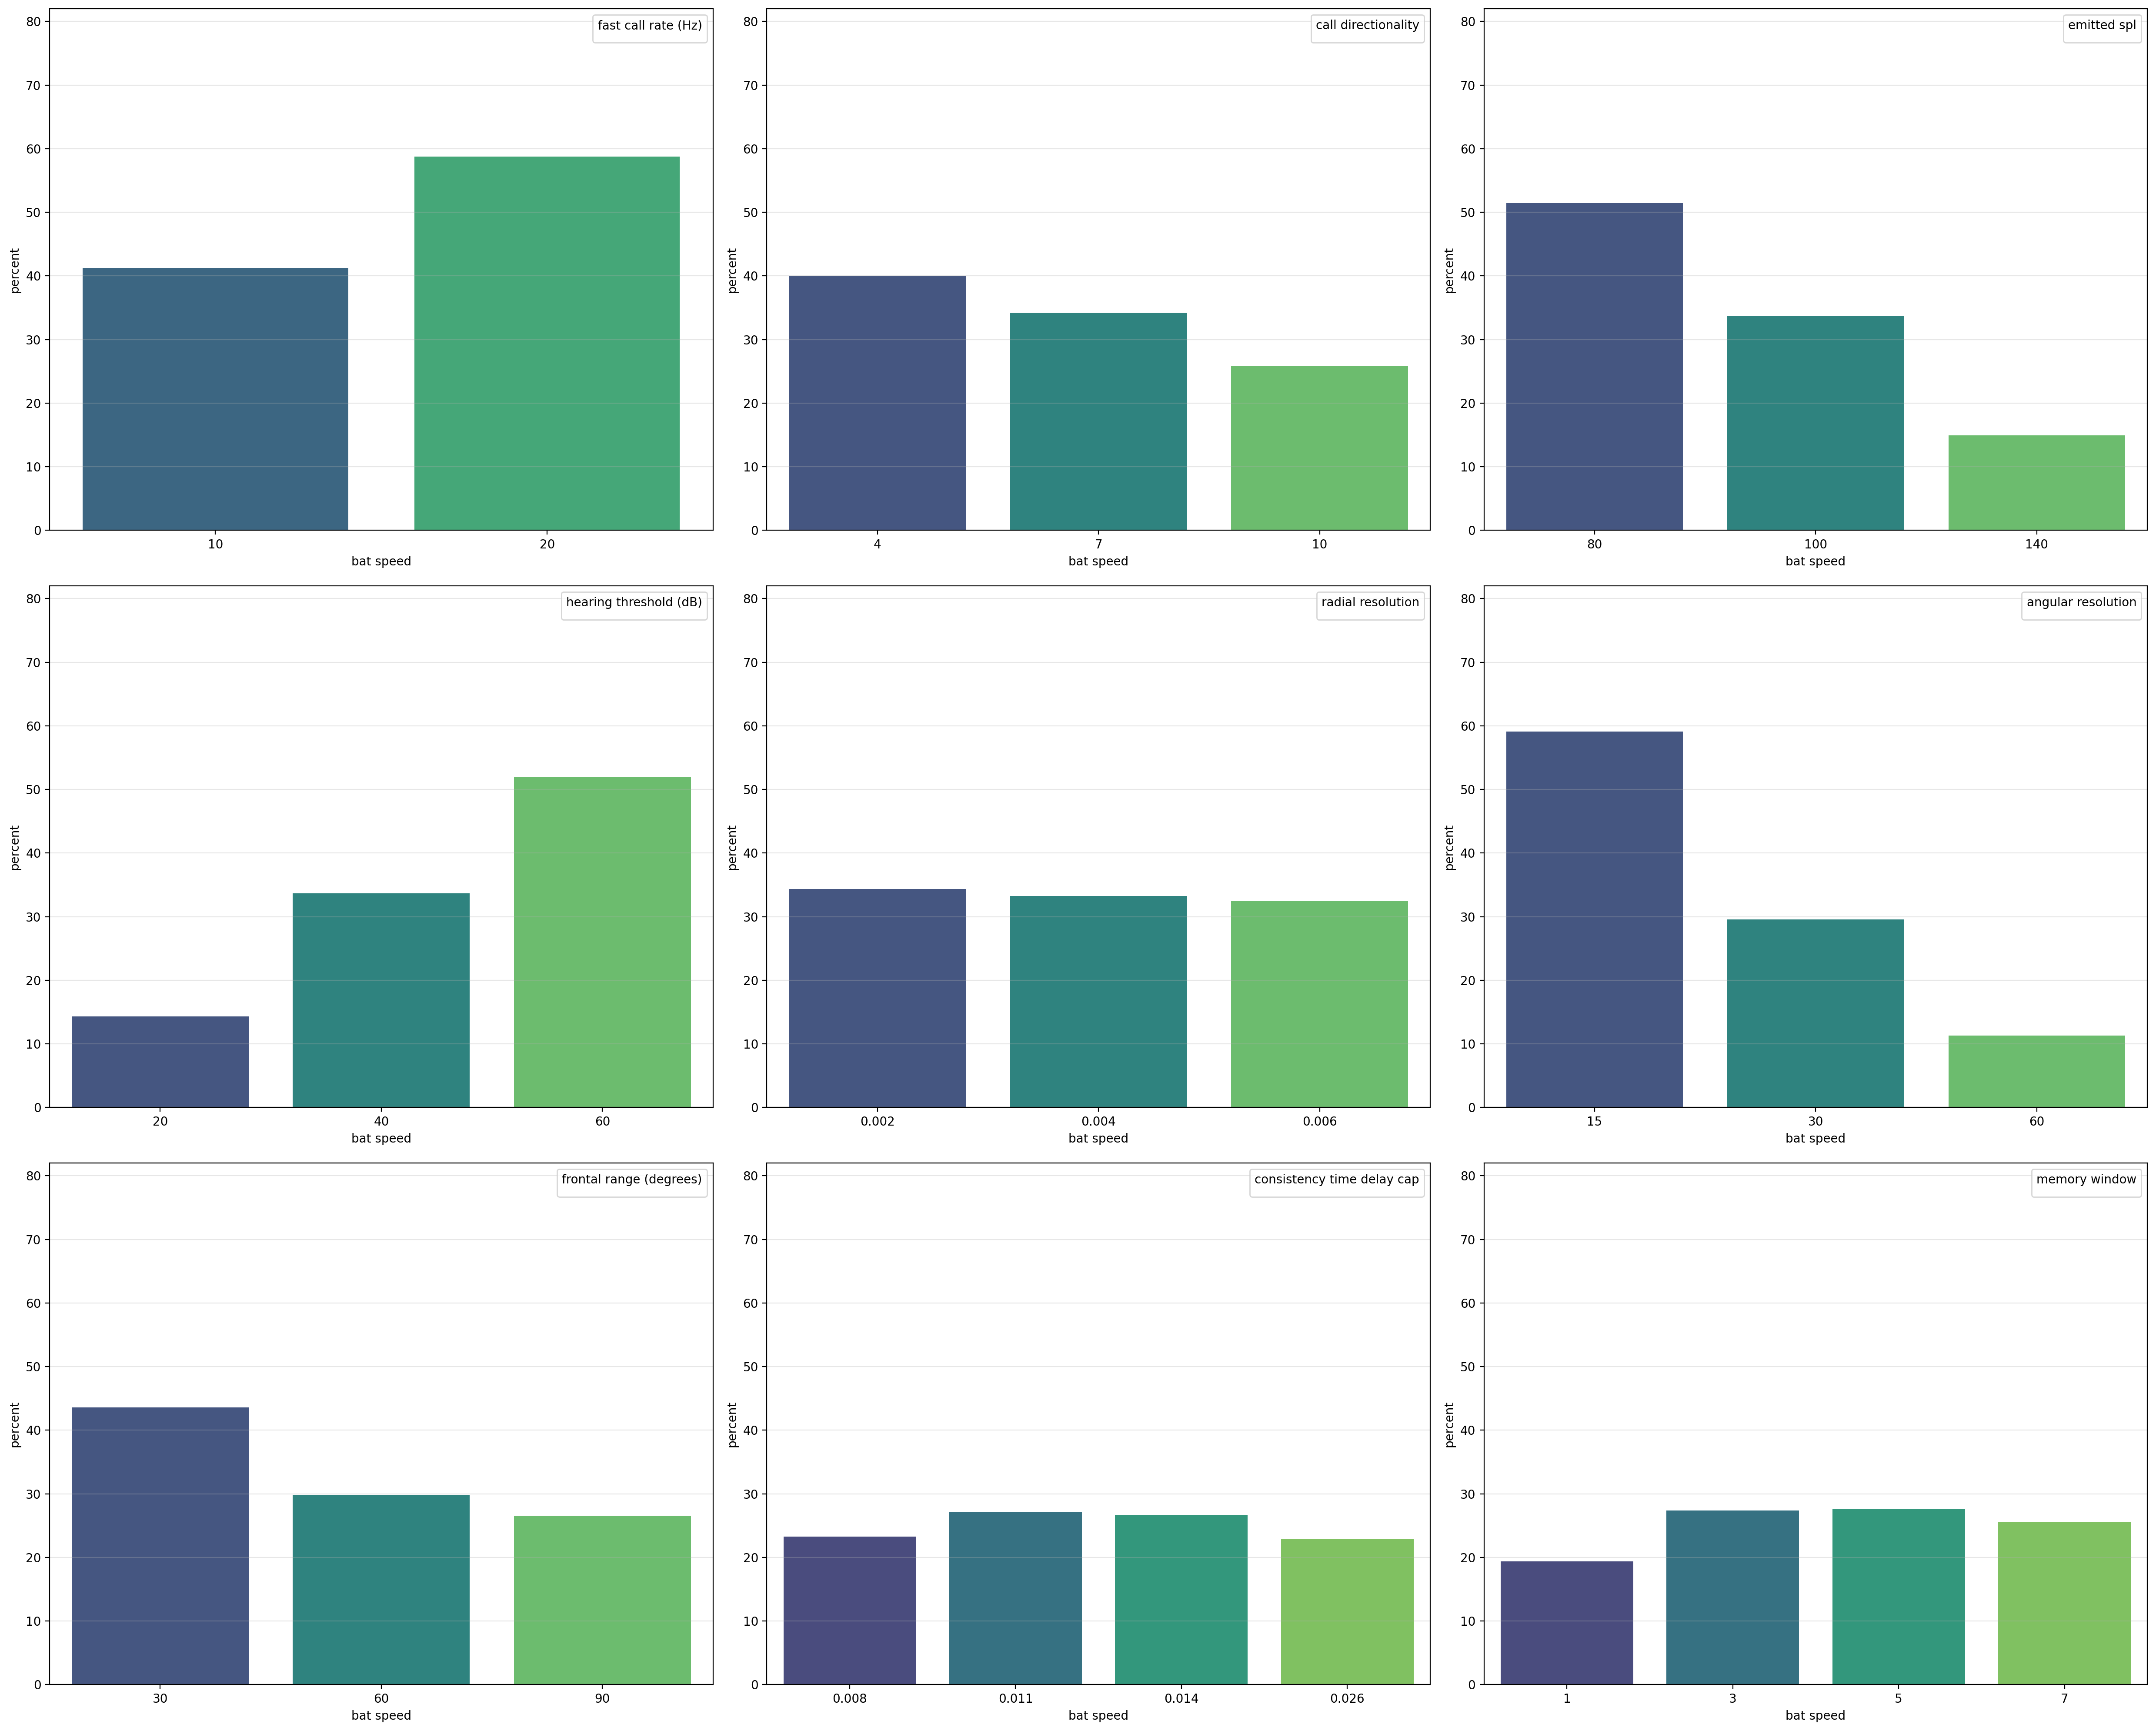

In [ ]:

plt.figure(figsize=(25,20))
number_of_subfigs = int(np.ceil(number_of_params/3))
bat_speeds = [1,3,5]

for i, param in enumerate(varying_params):
    df_low_collisions_given_bat_speed = scores_dataframe[scores_dataframe["wall collision total"]<5]
    plt.subplot(3,number_of_subfigs,i+1)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    sns.countplot(df_low_collisions_given_bat_speed, x=param, stat="percent", palette="viridis")
    plt.ylim(0,82)
    plt.xlabel("bat speed")
    # plt.legend(title="balls")
    plt.legend(title= labels[list(varying_params).index(param)])
    
plt.savefig("param_counts_10.svg", transparent= True)
plt.show()
plt.clf()

/tmp/marimo_2590111/__marimo__cell_VtFJ_.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df_low_durations_given_bat_speed, x=param_d, stat="percent", palette="viridis")
/tmp/marimo_2590111/__marimo__cell_VtFJ_.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df_low_durations_given_bat_speed, x=param_d, stat="percent", palette="viridis")
/tmp/marimo_2590111/__marimo__cell_VtFJ_.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(df_low_durations_given_bat_speed, x=param_d, stat="percent", palette="viridis")
/tmp/marimo_2590111/__

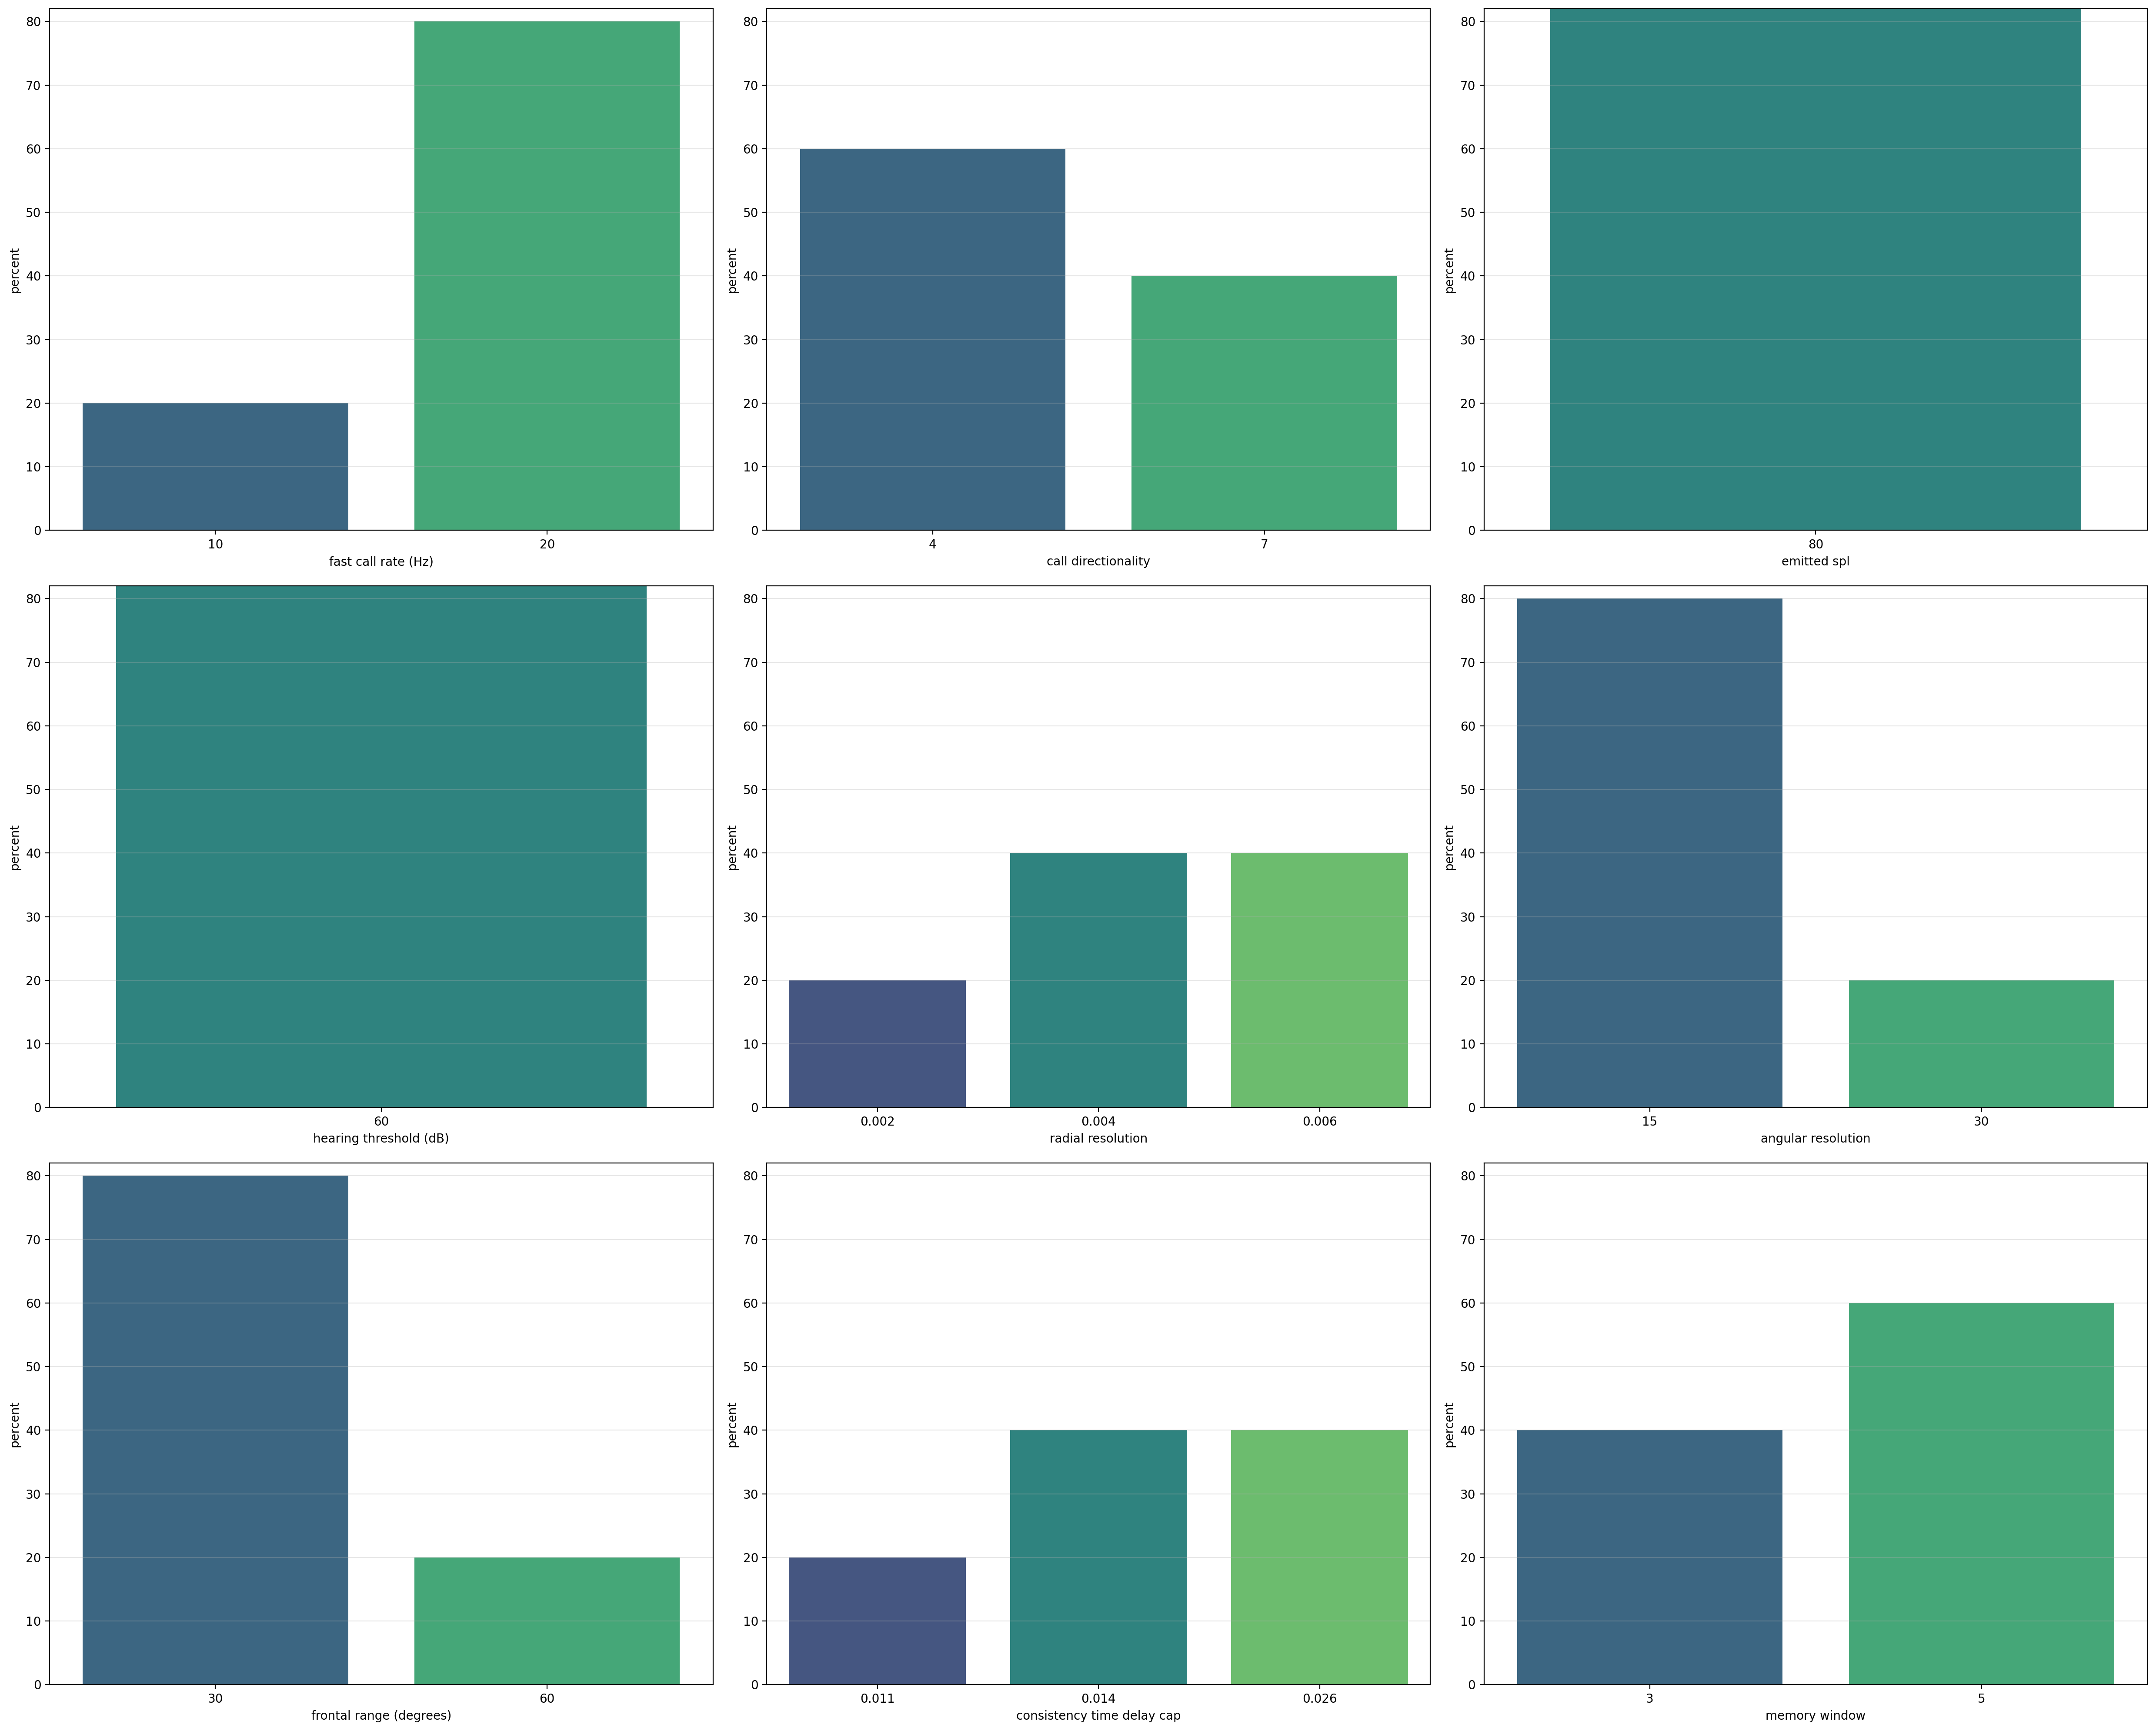

In [ ]:
plt.figure(figsize=(25,20))
for i_d, param_d in enumerate(varying_params):
    df_low_durations_given_bat_speed = scores_dataframe[(scores_dataframe["duration"]<25000) & (scores_dataframe["wall collision total"]<5) & (scores_dataframe["space_occupied"]>130)]
    plt.subplot(3,number_of_subfigs,i_d+1)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    sns.countplot(df_low_durations_given_bat_speed, x=param_d, stat="percent", palette="viridis")
    plt.ylim(0,82)
    plt.xlabel(labels[list(varying_params).index(param_d)])
    # plt.legend(title="balls")
    # plt.legend(title= labels[list(varying_params).index(param_d)])
    
plt.savefig("param_counts_10.svg", transparent= True)
plt.show()
plt.clf()

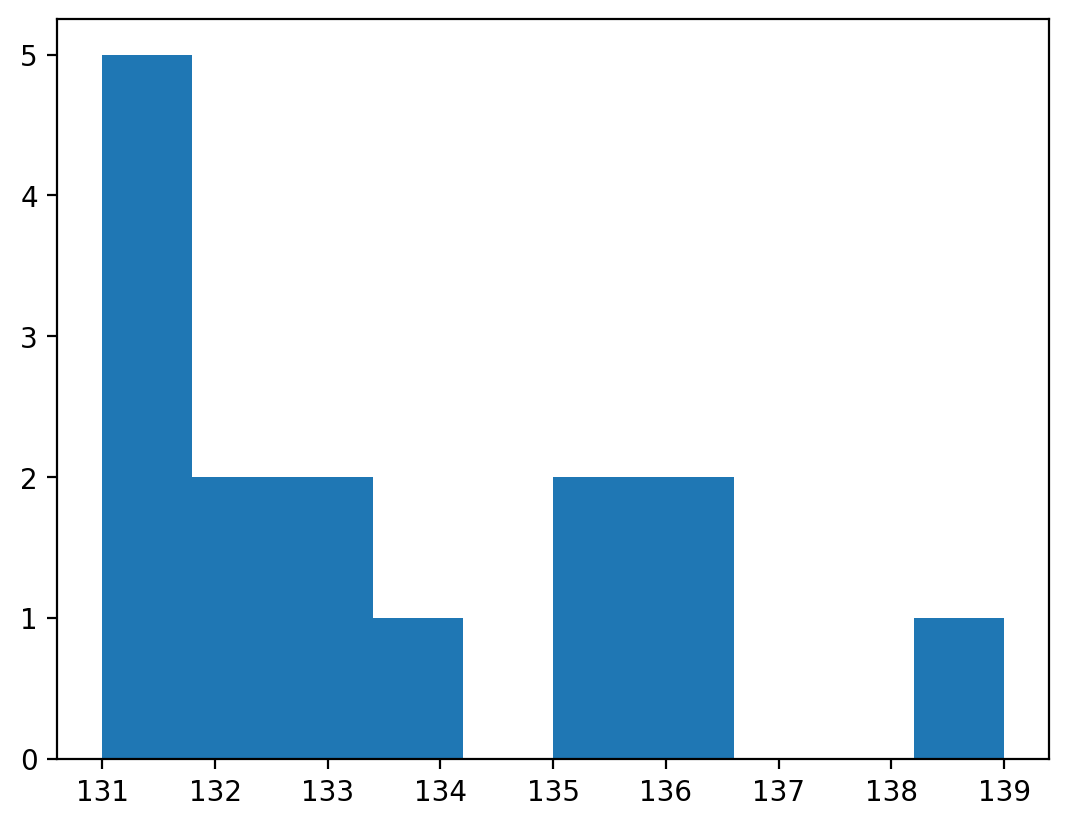

In [ ]:
plt.hist(df_low_durations_given_bat_speed["space_occupied"])
plt.show()
plt.hist(df_low_durations_given_bat_speed["wall collision total"])